# TIME COHORT ANALYSIS

## Time Cohort Analysis: Do New Customers Come Back?

# Project Overview

This project is a follow-up to my Market Basket Analysis, which looked at what UK online retail customers buy together. That analysis found that customers buy in product families, such as Regency teacup sets, herb markers, jumbo bags and Charlotte bags, and that several of those families are seasonal.

The market basket analysis described what is in a customer’s basket. It did not say whether those customers come back. This project looks at that missing piece with cohort analysis, and then connects it to the product families found earlier.

### What Is Cohort Analysis?

A cohort is a group of customers who share a starting point. In this project, the starting point is the month of a customer’s first purchase. Cohort analysis follows each group over the months that follow and measures how many of them buy again.

Looking at all customers together hides important differences. A business can have healthy-looking monthly sales while losing most of its new customers after one order, because a steady stream of new customers replaces them. Cohorts separate the two. They show how long customers stay active, when they drop off, and whether newer customers behave differently from older ones.

### About the Dataset

The data is transaction-level records from a UK-based online gift retailer, covering 2010-12-01 to 2011-11-30. Each row is one line item on an invoice, with the invoice number and date, product code and description, quantity, unit price, customer ID and country.

The analysis uses the same cleaned dataset as the market basket project, restricted to UK orders. One additional step is needed for cohorts: rows without a customer ID are removed, because a customer can’t be followed over time without one. The market basket analysis worked at the invoice level and didn’t need this. 25% of rows were removed.

### Business Questions

* How strong is overall customer retention? What share of new customers return in the month after their first purchase, and in the months that follow?
* Does retention differ between cohorts? Do customers who join in some months stay longer than others?
* How much do customers spend over time, and how do established customers differ from new ones?
  
### Approach
* Clean the data and keep UK orders with a customer ID.
* Assign each customer to a cohort based on the month of their first purchase, and calculate the number of months since that first purchase for every later order.
* Build the retention matrix and heatmap for the monthly cohorts.
* Calculate average spend per active customer and cumulative spend per acquired customer.
* Summarise the findings, limitations and recommendations.
* A follow-up notebook looks at cohorts by the product category of the first purchas

## Importing Libraries and Loading Data

In [1]:
#importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt
from python_tools import load_data, inspect_data

In [2]:
#loading data and inspecting the data
inspect_data(load_data('./data/online_retail_cleansed.csv'))

------- HEAD -------
   InvoiceNo StockCode                          Description  Quantity  \
0     536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1     536365     71053                  WHITE METAL LANTERN         6   
2     536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3     536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4     536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

           InvoiceDate  UnitPrice  CustomerID         Country  
0  2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1  2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2  2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3  2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4  2010-12-01 08:26:00       3.39     17850.0  United Kingdom  

 ------- SHAPE -------
(527918, 8)

 ------- INFO -------
<class 'pandas.DataFrame'>
RangeIndex: 527918 entries, 0 to 527917
Data columns (total 8 columns)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
527913,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
527914,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
527915,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
527916,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France


In [3]:
#cleaning data
data = (
    load_data('./data/online_retail_cleansed.csv')
    .dropna(subset = ['CustomerID']) #dropping the missing customer ID values
    .drop_duplicates() #dropping all the duplicates
    .assign(
        InvoiceDate = lambda x : pd.to_datetime(x['InvoiceDate']), #converting invoicedate to date time
        Revenue = lambda x : x['Quantity'] * x['UnitPrice'], #creating the revenue column
        CustomerID = lambda x : x['CustomerID'].astype(int), #change thecustomer ID data type to Int
        Month = lambda x : x['InvoiceDate'].dt.to_period('M') #creating a column called month
    )
    .query("Country == 'United Kingdom' and InvoiceDate < '2011-12-01'") #filter rows whose country is United Kingdom and dro data to the last month
)
inspect_data(data)

------- HEAD -------
   InvoiceNo StockCode                          Description  Quantity  \
0     536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1     536365     71053                  WHITE METAL LANTERN         6   
2     536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3     536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4     536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  Revenue    Month  
0 2010-12-01 08:26:00       2.55       17850  United Kingdom    15.30  2010-12  
1 2010-12-01 08:26:00       3.39       17850  United Kingdom    20.34  2010-12  
2 2010-12-01 08:26:00       2.75       17850  United Kingdom    22.00  2010-12  
3 2010-12-01 08:26:00       3.39       17850  United Kingdom    20.34  2010-12  
4 2010-12-01 08:26:00       3.39       17850  United Kingdom    20.34  2010-12  

 ------- SHAPE -------
(333398, 10)

 ------- INFO --

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Month
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12
...,...,...,...,...,...,...,...,...,...,...
502877,579885,85034C,3 ROSE MORRIS BOXED CANDLES,4,2011-11-30 17:37:00,1.25,15444,United Kingdom,5.00,2011-11
502878,579885,21742,LARGE ROUND WICKER PLATTER,2,2011-11-30 17:37:00,5.95,15444,United Kingdom,11.90,2011-11
502879,579885,23084,RABBIT NIGHT LIGHT,6,2011-11-30 17:37:00,2.08,15444,United Kingdom,12.48,2011-11
502880,579885,21257,VICTORIAN SEWING BOX MEDIUM,1,2011-11-30 17:37:00,7.95,15444,United Kingdom,7.95,2011-11


## EDA

In [4]:
#checking the minimum date and maximum date
date_min = data['InvoiceDate'].min()
date_max = data['InvoiceDate'].max()
print(f"The minimum date is: {date_min} \nThe maximum date is: {date_max}")

The minimum date is: 2010-12-01 08:26:00 
The maximum date is: 2011-11-30 17:37:00


In [5]:
#exploring the transactions, customer numbers and revenue for each month
monthly = data.groupby('Month').agg(
    transaction_numbers = ('InvoiceNo', 'nunique'),
    customer_numbers = ('CustomerID' , 'nunique'),
    revenue = ('Revenue', 'sum')
)
print(monthly)

         transaction_numbers  customer_numbers     revenue
Month                                                     
2010-12                 1288               815  496234.170
2011-01                  872               645  440781.930
2011-02                  893               678  354513.560
2011-03                 1175               879  465487.120
2011-04                 1055               784  406069.550
2011-05                 1401               962  541817.240
2011-06                 1248               888  523002.460
2011-07                 1193               856  483273.100
2011-08                 1126               833  494084.250
2011-09                 1558              1142  789612.621
2011-10                 1694              1228  812146.960
2011-11                 2381              1504  967576.050


<Axes: title={'center': 'Monthly transactions and active customers'}, xlabel='Month'>

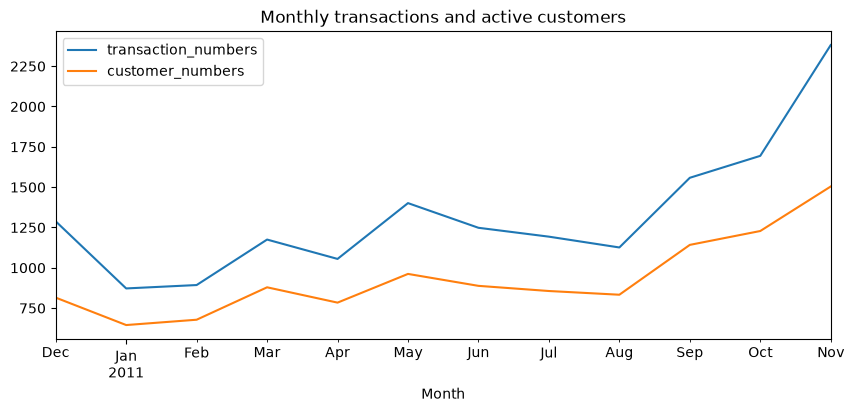

In [6]:
#visualizing the transaction and customer numbers
monthly[['transaction_numbers', 'customer_numbers']].plot(figsize=(10, 4), title='Monthly transactions and active customers')

<Axes: title={'center': 'Monthly Revenue Numbers'}, xlabel='Month'>

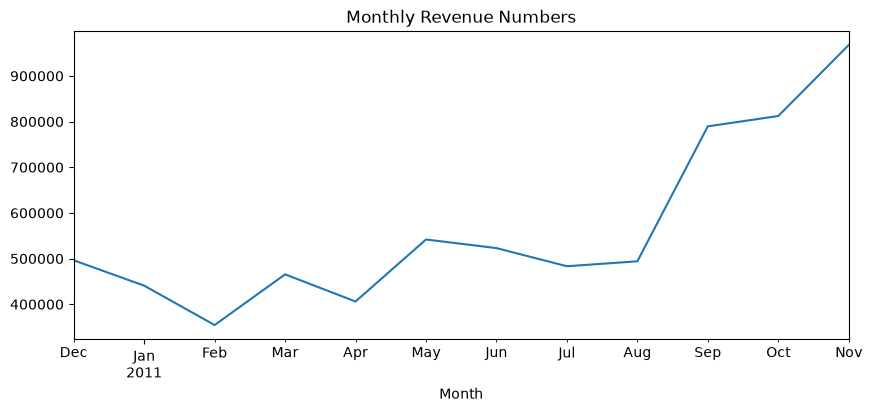

In [7]:
#visualizing the revenue numbers
monthly['revenue'].plot(figsize=(10, 4), title='Monthly Revenue Numbers')

<Axes: title={'center': 'New vs returning customers per month'}, xlabel='Month'>

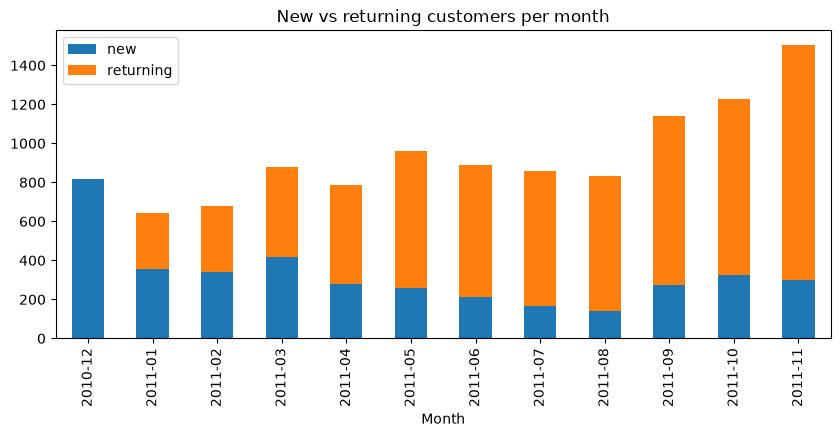

In [8]:
#the number of new and returning customers for each month
first_month = data.groupby('CustomerID')['Month'].min()
new_customers = first_month.value_counts().sort_index()
summary = pd.DataFrame({'active': monthly['customer_numbers'], 'new': new_customers}).fillna(0)
summary['returning'] = summary['active'] - summary['new']
summary[['new', 'returning']].plot(kind='bar', stacked=True, figsize=(10, 4),
                                   title='New vs returning customers per month')

## Cohort Analysis

### Time Cohort Analysis

In [9]:
#function the date object to the first day of the month
def get_month(x): return dt.datetime(x.year,x.month,1)
#truncating all date to the first day of the month
data['InvoiceMonth'] = data['InvoiceDate'].apply(get_month)
#creating the cohort month for each customer by assigning the smallest invoice month value to each customer
data['CohortMonth'] = data.groupby('CustomerID')['InvoiceMonth'].transform('min') 

In [10]:
#creating a function to extract the integer value for the year,month and day
def get_date_int(df,column):
    year = df[column].dt.year
    month = df[column].dt.month
    day = df[column].dt.day
    return year,month,day

invoice_year,invoice_month,_ = get_date_int(data,'InvoiceMonth')
cohort_year,cohort_month,_ = get_date_int(data,'CohortMonth')
year_diff = invoice_year - cohort_year
month_diff = invoice_month - cohort_month
data['CohortIndex'] = year_diff * 12 + month_diff + 1

In [11]:
#calculating the number of active customers each month from each cohort
grouping = data.groupby(['CohortMonth','CohortIndex'])
cohort_data = grouping['CustomerID'].apply(pd.Series.nunique)
cohort_data = cohort_data.reset_index()
cohort_counts = cohort_data.pivot(
    index = 'CohortMonth',
    columns = 'CohortIndex',
    values = 'CustomerID'
)
cohort_counts

CohortIndex,1,2,3,4,5,6,7,8,9,10,11,12
CohortMonth,,,,,,,,,,,,
2010-12-01,815.0,288.0,263.0,303.0,293.0,323.0,290.0,277.0,288.0,325.0,298.0,404.0
2011-01-01,357.0,75.0,93.0,84.0,118.0,99.0,90.0,86.0,107.0,117.0,127.0,NaN
2011-02-01,340.0,64.0,66.0,98.0,98.0,85.0,88.0,94.0,90.0,104.0,NaN,NaN
2011-03-01,419.0,64.0,109.0,83.0,94.0,69.0,111.0,96.0,119.0,NaN,NaN,NaN
2011-04-01,277.0,58.0,56.0,60.0,56.0,61.0,61.0,73.0,NaN,NaN,NaN,NaN
2011-05-01,256.0,48.0,44.0,44.0,53.0,58.0,68.0,NaN,NaN,NaN,NaN,NaN
2011-06-01,214.0,38.0,31.0,51.0,51.0,69.0,NaN,NaN,NaN,NaN,NaN,NaN
2011-07-01,168.0,30.0,33.0,39.0,47.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08-01,141.0,31.0,32.0,34.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


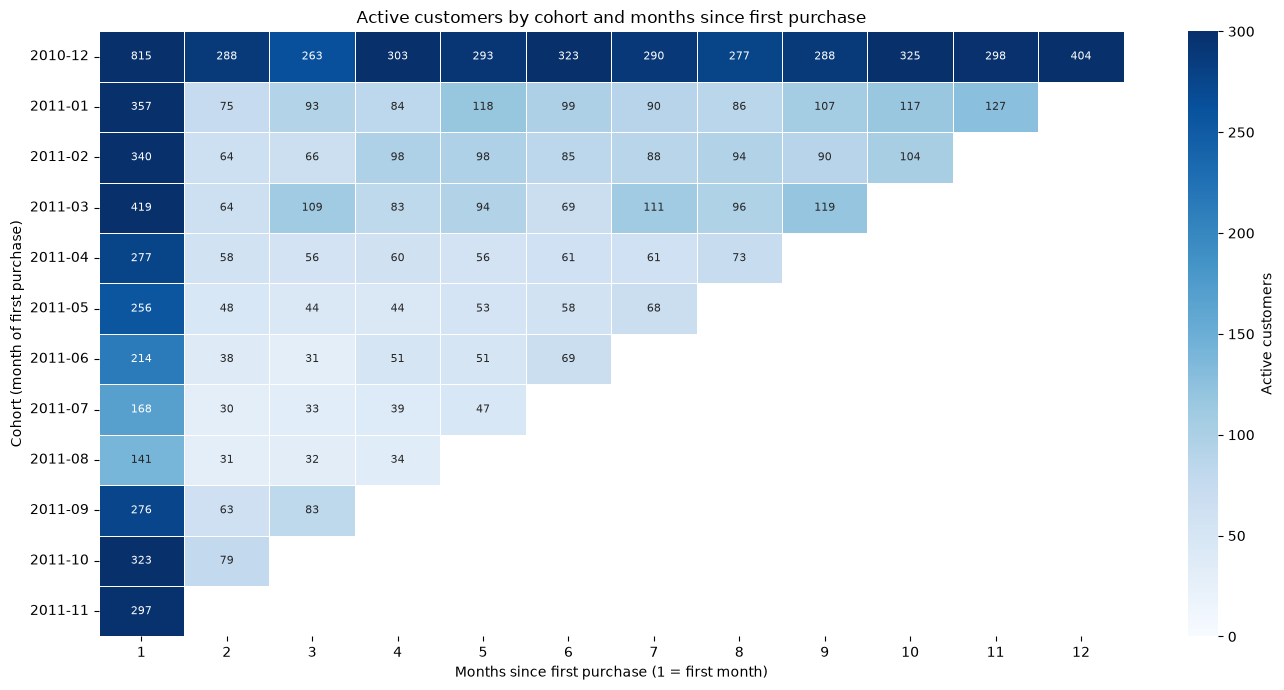

In [12]:
# visualizing cohort counts
counts = cohort_counts.copy()
counts.index = counts.index.strftime('%Y-%m')

plt.figure(figsize=(14, 7))
sns.heatmap(
    counts,
    annot=True, fmt='.0f', annot_kws={'size': 8},
    cmap='Blues',
    vmin=0, vmax=300,
    linewidths=0.5, linecolor='white',
    cbar_kws={'label': 'Active customers'}
)
plt.title('Active customers by cohort and months since first purchase')
plt.xlabel('Months since first purchase (1 = first month)')
plt.ylabel('Cohort (month of first purchase)')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Retention Rate

In [13]:
#creating retention percentage cohort table
cohort_sizes = cohort_counts.iloc[:,0]
retention = cohort_counts.divide(cohort_sizes,axis = 0)
retention = retention.round(3) * 100
retention

CohortIndex,1,2,3,4,5,6,7,8,9,10,11,12
CohortMonth,,,,,,,,,,,,
2010-12-01,100.0,35.3,32.3,37.2,36.0,39.6,35.6,34.0,35.3,39.9,36.6,49.6
2011-01-01,100.0,21.0,26.1,23.5,33.1,27.7,25.2,24.1,30.0,32.8,35.6,NaN
2011-02-01,100.0,18.8,19.4,28.8,28.8,25.0,25.9,27.6,26.5,30.6,NaN,NaN
2011-03-01,100.0,15.3,26.0,19.8,22.4,16.5,26.5,22.9,28.4,NaN,NaN,NaN
2011-04-01,100.0,20.9,20.2,21.7,20.2,22.0,22.0,26.4,NaN,NaN,NaN,NaN
2011-05-01,100.0,18.8,17.2,17.2,20.7,22.7,26.6,NaN,NaN,NaN,NaN,NaN
2011-06-01,100.0,17.8,14.5,23.8,23.8,32.2,NaN,NaN,NaN,NaN,NaN,NaN
2011-07-01,100.0,17.9,19.6,23.2,28.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08-01,100.0,22.0,22.7,24.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


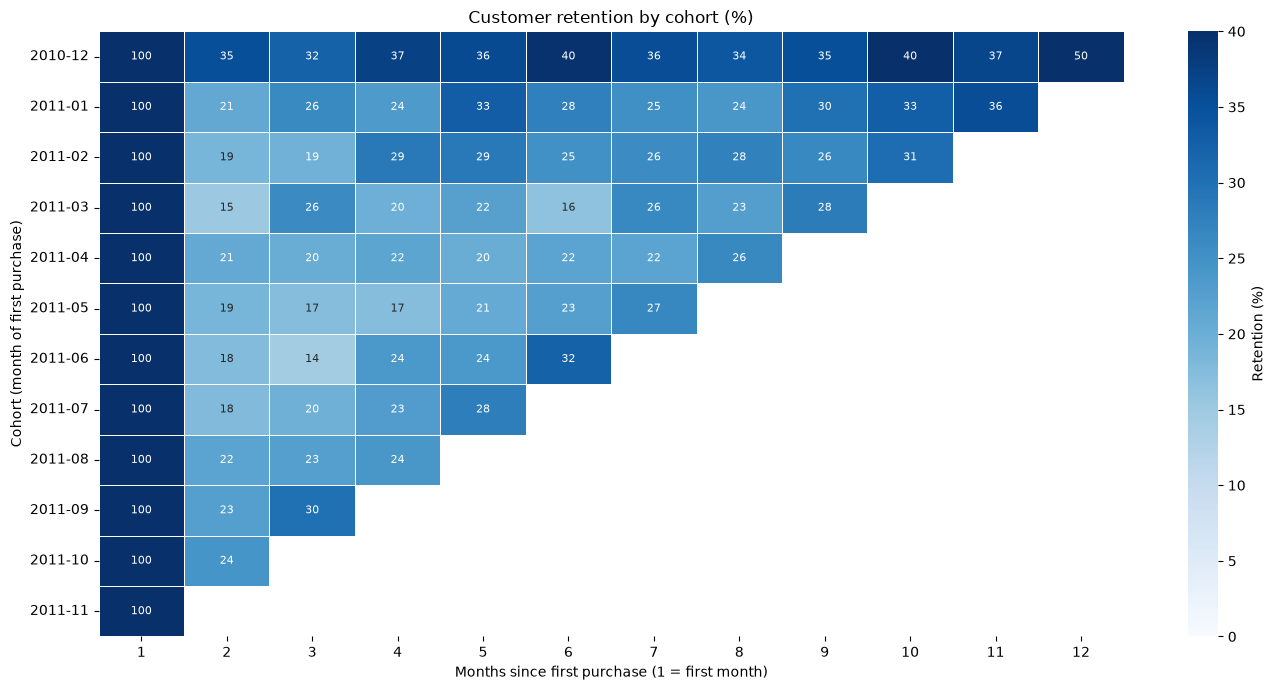

In [14]:
#visualizing retention percentage
retention_plot = retention.copy()
retention_plot.index = retention_plot.index.strftime('%Y-%m')

plt.figure(figsize=(14, 7))
sns.heatmap(
    retention_plot,
    annot=True, fmt='.0f', annot_kws={'size': 8},
    cmap='Blues',
    vmin=0, vmax=40,
    linewidths=0.5, linecolor='white',
    cbar_kws={'label': 'Retention (%)'}
)
plt.title('Customer retention by cohort (%)')
plt.xlabel('Months since first purchase (1 = first month)')
plt.ylabel('Cohort (month of first purchase)')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Cohort Spend

In [15]:
#calculating the average spend for each cohort overtime
cohort_spend = (grouping['Revenue'].sum()
    .reset_index()
    .pivot(index = 'CohortMonth',columns = 'CohortIndex',values = 'Revenue'))
average_spend = (cohort_spend / cohort_counts).round(2)
average_spend

CohortIndex,1,2,3,4,5,6,7,8,9,10,11,12
CohortMonth,,,,,,,,,,,,
2010-12-01,608.88,691.25,698.51,761.70,601.78,811.01,859.46,852.65,890.82,1170.39,1169.50,1026.47
2011-01-01,677.04,449.77,421.53,706.19,492.01,507.38,633.80,491.53,562.07,613.00,793.05,NaN
2011-02-01,403.16,400.86,498.13,451.54,394.24,361.57,483.79,596.75,563.70,551.77,NaN,NaN
2011-03-01,405.33,434.92,521.68,457.36,494.46,504.71,510.46,636.11,557.91,NaN,NaN,NaN
2011-04-01,396.09,448.20,411.01,383.64,437.93,408.66,440.43,423.43,NaN,NaN,NaN,NaN
2011-05-01,369.90,346.75,381.53,393.23,486.66,434.31,407.78,NaN,NaN,NaN,NaN,NaN
2011-06-01,501.26,319.55,321.21,392.62,409.39,426.63,NaN,NaN,NaN,NaN,NaN,NaN
2011-07-01,362.42,320.01,359.33,397.30,316.19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08-01,400.52,591.31,897.65,1063.41,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


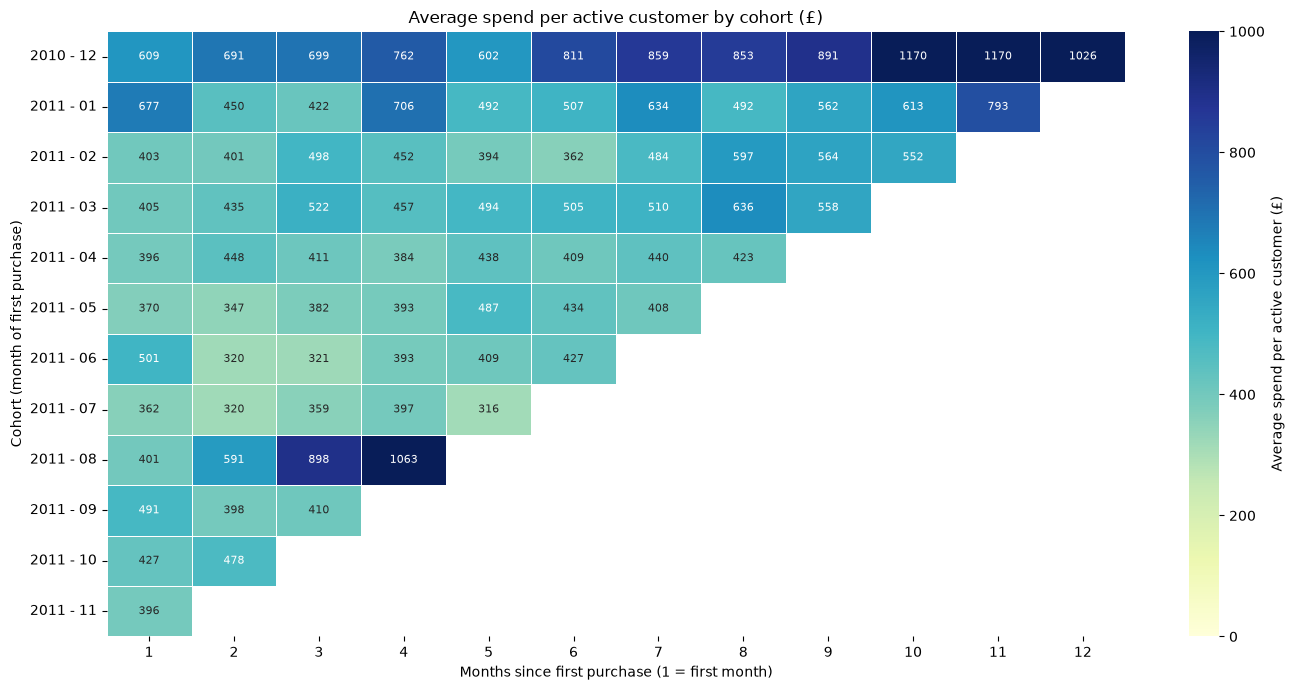

In [16]:
#visualizing the average spend cohort table
spend_plot = average_spend.copy()
spend_plot.index = spend_plot.index.strftime('%Y - %m')
plt.figure(figsize=(14, 7))
sns.heatmap(
    spend_plot,
    annot=True, fmt='.0f', annot_kws={'size': 8},
    cmap='YlGnBu',
    vmin=0, vmax=1000,
    linewidths=0.5, linecolor='white',
    cbar_kws={'label': 'Average spend per active customer (£)'}
)
plt.title('Average spend per active customer by cohort (£)')
plt.xlabel('Months since first purchase (1 = first month)')
plt.ylabel('Cohort (month of first purchase)')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [17]:
#cummulative spend per customer
revenue_per_acquired = cohort_spend.divide(cohort_sizes, axis=0)
cumulative_value = revenue_per_acquired.cumsum(axis=1).round(2)
cumulative_value

CohortIndex,1,2,3,4,5,6,7,8,9,10,11,12
CohortMonth,,,,,,,,,,,,
2010-12-01,608.88,853.15,1078.55,1361.74,1578.09,1899.51,2205.33,2495.12,2809.91,3276.63,3704.25,4213.08
2011-01-01,677.04,771.53,881.34,1047.50,1210.12,1350.83,1510.61,1629.02,1797.48,1998.38,2280.50,NaN
2011-02-01,403.16,478.61,575.31,705.46,819.09,909.48,1034.70,1199.68,1348.90,1517.68,NaN,NaN
2011-03-01,405.33,471.76,607.47,698.07,809.00,892.12,1027.34,1173.09,1331.54,NaN,NaN,NaN
2011-04-01,396.09,489.93,573.03,656.12,744.66,834.65,931.64,1043.23,NaN,NaN,NaN,NaN
2011-05-01,369.90,434.92,500.49,568.08,668.83,767.23,875.55,NaN,NaN,NaN,NaN,NaN
2011-06-01,501.26,558.01,604.54,698.10,795.67,933.23,NaN,NaN,NaN,NaN,NaN,NaN
2011-07-01,362.42,419.57,490.15,582.38,670.84,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08-01,400.52,530.52,734.25,990.67,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


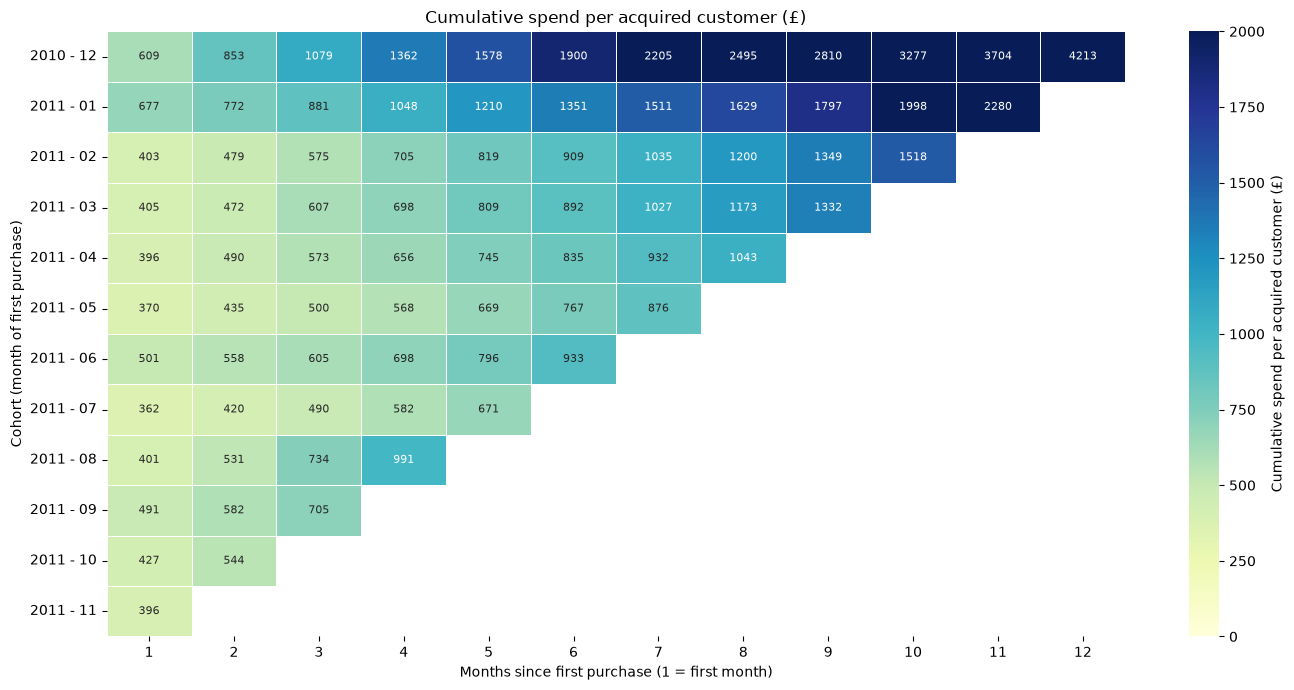

In [18]:
#visualizing cumulative_value
cummulative_plot = cumulative_value.copy()
cummulative_plot.index = cummulative_plot.index.strftime('%Y - %m')
plt.figure(figsize=(14, 7))
sns.heatmap(
    cummulative_plot,
    annot=True, fmt='.0f', annot_kws={'size': 8},
    cmap='YlGnBu',
    vmin=0, vmax=2000,
    linewidths=0.5, linecolor='white',
    cbar_kws={'label': 'Cumulative spend per acquired customer (£)'}
)
plt.title('Cumulative spend per acquired customer (£)')
plt.xlabel('Months since first purchase (1 = first month)')
plt.ylabel('Cohort (month of first purchase)')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [19]:
#to check key figures in 2nd month average retention,revenue contribution of Sep to November and returning clients in November
month2_retention = retention[2].iloc[1:].mean()                                  
sep_nov_contribution = monthly['revenue'].iloc[-3:].sum() / monthly['revenue'].sum()
nov_returning_percentage = 1 - cohort_counts[1].iloc[-1] / monthly['customer_numbers'].iloc[-1]
print(f"the 2nd month retention percentage {month2_retention}\nThe revenue contribution between September and November {sep_nov_contribution}\nThe share of returning customers in November is {nov_returning_percentage}")

the 2nd month retention percentage 19.98
The revenue contribution between September and November 0.37926017862136757
The share of returning customers in November is 0.8025265957446809


# Key Findings and Recomendations

## Key Findings

Scope: UK customers, 1 Dec 2010 to 30 Nov 2011. December 2011 is excluded because the data stops on 9 December.

1. Sales are strongly seasonal, with a sharp autumn peak.
Monthly revenue sits at roughly £350k to £540k from December to August, then jumps to about £790k in September, £810k in October and £970k in November. Transactions rise from about 1,130 in August to about 2,390 in November, and active customers from about 835 to about 1,505. September to November account for roughly 38% of the year’s revenue.

2. Most new customers buy once, and those who return keep returning.
About 20% of new customers (range 15 to 24%) buy again in their second month, so roughly four in five don’t. After that, retention doesn’t keep falling. It stays at around 17 to 30% for the rest of the year. This suggests a loyal core of customers who buy periodically, plus a large group of one-time buyers.

3. November pulls customers back across every cohort.
Reading the heatmap diagonally, November is the brightest month for every cohort (24 to 50%, against about 20 to 25% in most other months). Customers who had gone quiet return for the Christmas season, so month-to-month “retention” here partly reflects seasonal buying and not just who has stayed.

4. New-customer acquisition slowed in summer, and the business leaned on returning customers.
New customers per month fell from 419 in March to 141 in August, then recovered to 276 to 323 in September to November. Returning customers made up about 80% of active customers in November (about 1,200 of 1,500).

5. Established customers are both more loyal and higher-spending.
The customers already active in December 2010 retained at 32 to 40% (50% in November) and spent £600 to £1,170 per active customer. New 2011 cohorts retained at about 20% and spent £360 to £500 in their first month. Over 12 months, the December 2010 group spent £4,213 per customer, against £2,280 over 11 months for the January cohort and about £770 to £930 over 6 months for spring cohorts.

6. A new customer’s value builds slowly.
A new customer spends about £400 in their first month. By month 6, cumulative spend is typically £770 to £930, roughly double the first month. About half of a new customer’s six-month value comes after the first order.

7. Customers acquired just before the peak are worth more, sooner.
The August cohort had spent £991 per customer by month 4 (November), against £570 to £705 for February to July cohorts at the same age.However, this cohort is small (about 31 to 34 active customers a month) this statement should be treated as a pointer, not a proven effect.

## Recommendations
1. **Create a first-30-days programme**. The biggest drop is between the first and second month, when about 80% of new customers don’t return. Follow up two to three weeks after a first order with a reorder reminder, a bundle suggestion based on the market basket analysis (for example the Regency teacup set) or a small second-order incentive. The baseline to beat is about 20% month-2 retention.
2. **Prepare for autumn from August**. Stock the seasonal ranges early, and run a win-back campaign for customers who have gone quiet in late August and early September, since many of them return in the autumn peak.
3. **Test acquiring customers in August to October**. Customers acquired just before the peak reached higher spend sooner, and acquisition was weakest in summer. Run a small test before shifting budget, given the small cohort behind this finding.
4. **Protect the loyal core**. Established customers spend roughly twice as much per active month and return far more often. Identify them using an RFM segmentation, give them priority on stock availability, and consider direct account contact.
5. **Judge cohorts by the same calendar months**. Compare cohorts using equivalent months, so the November bump isn’t mistaken for improved loyalty.


# Limitations
* Only 12 months of data, so seasonality can’t be separated from trend.
* The December 2010 group is every customer active that month, including long-standing ones, so it isn’t a true new-customer cohort. The January cohort (retention up to 36%, spend up to £793) may also include customers who bought before December 2010, so early-2011 new-customer counts are probably overstated.
* Cohorts are small (141 to 419 customers), so differences of a few percentage points may be noise.
* Retention counts any purchase in a month, so customers who buy every second or third month appear to “leave” and “return”.
* Averages are affected by a small number of large wholesale-style buyers.